In [1]:
!pip install pyreadr igraph cairocffi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.4/788.4 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 80.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 5.1 MB/s eta 0:00:00


In [3]:
import pyreadr

result = pyreadr.read_r("congress.RData")

print(result.keys())

odict_keys(['congress'])


In [4]:
for name, df in result.items():
    print("\nOBJECT:", name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    display(df.head())


OBJECT: congress
Shape: (220, 11)
Columns: ['bioguide_id', 'first_name', 'last_name', 'full_name', 'gender', 'party', 'state', 'chamber', 'birth_year', 'twitter', 'wikipedia_id']


,bioguide_id,first_name,last_name,full_name,gender,party,state,chamber,birth_year,twitter,wikipedia_id
rownames,,,,,,,,,,,
1,B001000,James,Moore,James Moore,M,Democrat,FL,Senate,1951.0,SenMoore70,James_Moore
2,B001001,Patricia,Johnson,Patricia Johnson,F,Democrat,IA,Senate,1977.0,SenJohnson72,Patricia_Johnson
3,B001002,Sarah,Lewis,Sarah Lewis,F,Republican,AL,Senate,1955.0,SenLewis44,Sarah_Lewis
4,B001003,Mark,Miller,Mark Miller,M,Democrat,CT,Senate,1967.0,SenMiller78,Mark_Miller
5,B001004,Brian,Wright,Brian Wright,M,Democrat,MO,Senate,1950.0,SenWright81,Brian_Wright


In [13]:
import pandas as pd
import igraph as ig

In [16]:
import pyreadr

committee_result = pyreadr.read_r("/content/committees.RData")

print(committee_result.keys())

odict_keys(['committees'])


In [17]:
committees = committee_result["committees"]

print("Shape:", committees.shape)
print("Columns:", committees.columns.tolist())

display(committees.head())

Shape: (211, 5)
Columns: ['bioguide_id', 'committee_id', 'committee_name', 'rank', 'party']


,bioguide_id,committee_id,committee_name,rank,party
rownames,,,,,
1,B001000,SSAS,Committee on Armed Services,5.0,Democrat
2,B001000,SSBU,Committee on the Budget,2.0,Democrat
3,B001000,SSFI,Committee on Finance,7.0,Democrat
4,B001001,SSEV,Committee on Environment and Public Works,10.0,Democrat
5,B001001,SSFI,Committee on Finance,11.0,Democrat


In [18]:
print(committees.dtypes)

bioguide_id        object
committee_id       object
committee_name     object
rank              float64
party              object
dtype: object


In [19]:
common_committees = (
    committees[["bioguide_id", "committee_id"]]
    .merge(
        committees[["bioguide_id", "committee_id"]],
        on="committee_id"
    )
)

In [20]:
common_committees = common_committees[
    common_committees["bioguide_id_x"] != common_committees["bioguide_id_y"]
].copy()

In [21]:
common_committees["member1"] = common_committees[
    ["bioguide_id_x", "bioguide_id_y"]
].min(axis=1)

common_committees["member2"] = common_committees[
    ["bioguide_id_x", "bioguide_id_y"]
].max(axis=1)

common_committees = common_committees[
    ["member1", "member2", "committee_id"]
].drop_duplicates()

In [22]:
common_committees = (
    common_committees
    .groupby(["member1", "member2"])
    .size()
    .reset_index(name="shared_committees")
)

In [23]:
print("Shape:", common_committees.shape)
display(common_committees.head(10))


Shape: (1651, 3)


,member1,member2,shared_committees
0,B001000,B001001,1
1,B001000,B001003,1
2,B001000,B001004,1
3,B001000,B001005,1
4,B001000,B001006,2
5,B001000,B001007,1
6,B001000,B001014,1
7,B001000,B001016,1
8,B001000,B001018,1
9,B001000,B001019,1


In [26]:
all_members = pd.concat([common_committees["member1"], common_committees["member2"]]).unique()
member_df = pd.DataFrame({'name': all_members})

g = ig.Graph.DataFrame(
    common_committees[["member1", "member2"]],
    directed=False,
    vertices=member_df,
    use_vids=False
)

In [27]:
print("Number of vertices:", g.vcount())
print("Number of edges:", g.ecount())

Number of vertices: 100
Number of edges: 1651


In [28]:
common_3 = common_committees[
    common_committees["shared_committees"] >= 3
].copy()

display(common_3.head())

,member1,member2,shared_committees
222,B001006,B001061,3
287,B001008,B001022,3
844,B001026,B001057,3


In [30]:
all_members_g3 = pd.concat([common_3["member1"], common_3["member2"]]).unique()
member_df_g3 = pd.DataFrame({'name': all_members_g3})

g3 = ig.Graph.DataFrame(
    common_3[["member1", "member2"]],
    directed=False,
    vertices=member_df_g3,
    use_vids=False
)

In [31]:
print("Number of edges:", g3.ecount())

Number of edges: 3


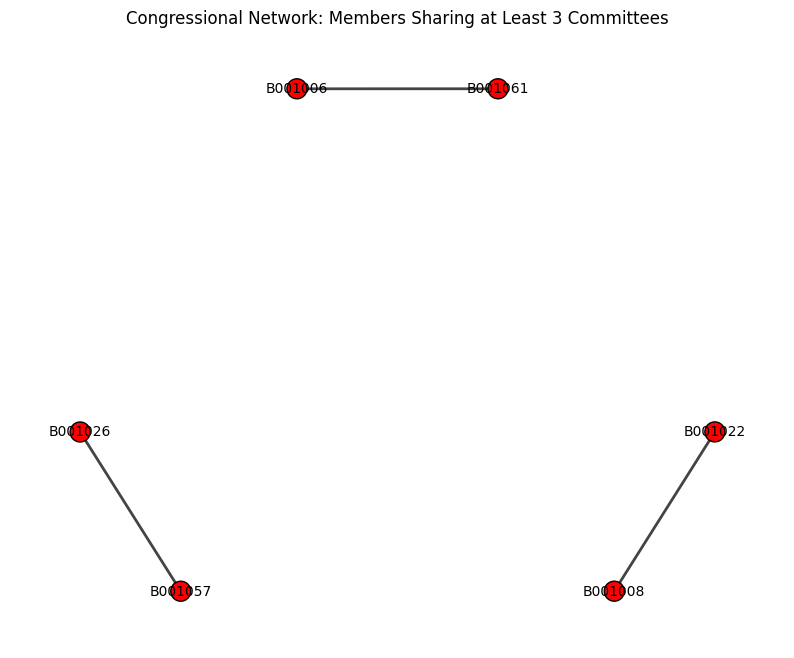

In [32]:
import matplotlib.pyplot as plt
layout = g3.layout("fr")
fig, ax = plt.subplots(figsize=(10, 8))

ig.plot(
    g3,
    target=ax,
    layout=layout,
    vertex_size=20,
    vertex_label=g3.vs["name"],
    vertex_label_size=10,
    edge_width=2
)

plt.title("Congressional Network: Members Sharing at Least 3 Committees")
plt.show()


In [33]:
senators = congress[congress["chamber"] == "Senate"].copy()

print("Number of senators:", len(senators))

senator_ids = set(senators["bioguide_id"])

print("Number of senator IDs:", len(senator_ids))

senator_edges = common_committees[
    common_committees["member1"].isin(senator_ids) &
    common_committees["member2"].isin(senator_ids)
].copy()

print("Senator-only edges:", len(senator_edges))
display(senator_edges.head())

Number of senators: 100
Number of senator IDs: 100
Senator-only edges: 1651


,member1,member2,shared_committees
0,B001000,B001001,1
1,B001000,B001003,1
2,B001000,B001004,1
3,B001000,B001005,1
4,B001000,B001006,2


In [35]:
all_senator_members = pd.concat([senator_edges["member1"], senator_edges["member2"]]).unique()
senator_member_df = pd.DataFrame({'name': all_senator_members})

g_senators = ig.Graph.DataFrame(
    senator_edges[["member1", "member2"]],
    directed=False,
    vertices=senator_member_df,
    use_vids=False
)

In [36]:
print("Number of senator vertices:", g_senators.vcount())
print("Number of senator edges:", g_senators.ecount())

Number of senator vertices: 100
Number of senator edges: 1651


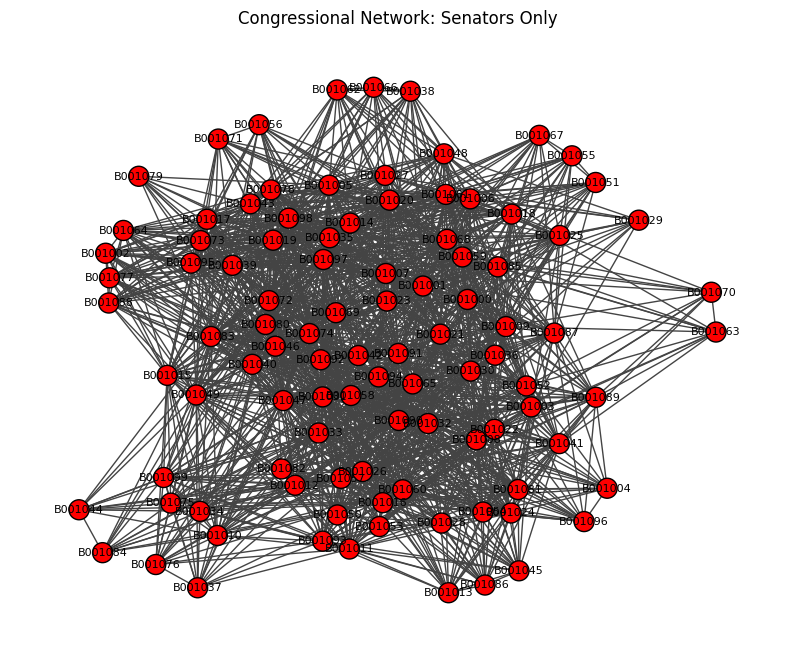

In [37]:
fig, ax = plt.subplots(figsize=(10, 8))

ig.plot(
    g_senators,
    target=ax,
    layout=g_senators.layout("fr"),
    vertex_size=20,
    vertex_label=g_senators.vs["name"],
    vertex_label_size=8,
    edge_width=1
)

plt.title("Congressional Network: Senators Only")
plt.show()